## LSTM Model for Crash Label Prediction

This section builds and trains an LSTM (Long Short-Term Memory) neural network to predict crash labels based on past 60 days of indicator values.

**Model Architecture:**
- **Input**: Sequences of 60 days × 69 indicator features
- **Output**: Binary crash label prediction (0 or 1)
- **Layers**: 
  - LSTM(128) with Dropout(0.2)
  - LSTM(64) with Dropout(0.2)
  - Dense(32) with Dropout(0.2)
  - Dense(1, sigmoid) for binary classification

**Data Processing:**
1. Merge crash_labels and indicators dataframes on date
2. Normalize indicator features using StandardScaler
3. Create sliding windows of 60-day sequences
4. Split into train (80%) and test (20%) sets with temporal order preserved

**Results:**
- Training history, ROC curve, and confusion matrix are displayed
- Model is saved for future use


In [1]:
import os
import pandas as pd
import numpy as np

import json
from tqdm import tqdm
import random
import matplotlib.pyplot as plt
import shutil
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
import base64
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')

np.random.seed(42)
random.seed(42)

In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

### Reading the outputs and embeddings

In [3]:
Market = 'CBU0'

In [4]:
# Getting OHLCV data for other market indexes
OHLCV_df_list = []
Market_list = ['SP500', 'STOXX', 'CAC', 'DAX', 'FTSE', 'CBU0']

for iter_Market in Market_list:
    if iter_Market != Market:
        df = pd.read_csv(f"Data/OHLCV/{iter_Market}_df_OHLCV.csv")

        # Add market suffix to all columns except Date
        df = df.rename(
            columns={col: f"{col}_{iter_Market}" for col in df.columns if col != 'Date'}
        )

        OHLCV_df_list.append(df)

# Merge all DataFrames on Date
OHLCV_df = OHLCV_df_list[0]

for df in OHLCV_df_list[1:]:
    OHLCV_df = OHLCV_df.merge(df, on='Date', how='outer')

OHLCV_df = OHLCV_df.sort_values('Date').reset_index(drop=True)

In [5]:
# Reading the crash labels from .csv file
crash_labels = pd.read_csv(f"Data/Indicators_crash/{Market}_df_Crash_Label.csv")
crash_labels = crash_labels.sort_values('date').reset_index(drop=True).ffill().dropna().reset_index(drop=True)
# Reading the indicators from .csv file
indicators = pd.read_csv(f"Data/Indicators_crash/{Market}_df_Indicators.csv")
print(f"Missing values in crash labels: {crash_labels.isna().sum().sum()}")
print(f"Missing values in indicators: {indicators.isna().sum().sum()}")

indicators = indicators.dropna()
print(indicators.shape)

indicators = indicators.merge(OHLCV_df, on='Date', how='inner')
cols = [col for col in indicators.columns if 'Date_' not in col]
indicators = indicators[cols]
indicators = indicators.dropna(axis=1)
print(indicators.shape)

Missing values in crash labels: 0
Missing values in indicators: 0
(2188, 64)
(2188, 76)


In [6]:
# Step 1: Prepare the data - align crash_labels and indicators on date
# Convert date columns to datetime
crash_labels['date'] = pd.to_datetime(crash_labels['date'])
indicators['Date'] = pd.to_datetime(indicators['Date'])


# Step 2: Extract indicator columns (exclude date and crash label related columns)
date_cols = ['date', 'Date']
label_cols = ['crash_label', 'min_future_logret', 'crash_threshold']
# indicator_cols = [col for col in merged_df.columns if col not in date_cols + label_cols]

### PCA and Selecting top n features

In [7]:
from sklearn.decomposition import PCA

news_embeddings_df = pd.read_csv(f'Data/{Market}_daily_news_embeddings.csv', parse_dates=['date'])
embedding_cols = [col for col in news_embeddings_df.columns if col != 'date']

components = 10  # Number of PCA components to keep

# Select only embedding/features columns
X = news_embeddings_df[embedding_cols].values

# PCA
pca = PCA(n_components=components, random_state=42)

X_pca = pca.fit_transform(X)

# Create DataFrame
pca_cols = [f"news_pca_{i}" for i in range(components)]

news_pca_df = pd.DataFrame(
    X_pca,
    columns=pca_cols,
    index=news_embeddings_df.index
)

# Keep date if needed
news_pca_df["date"] = news_embeddings_df["date"].values

print("Original shape:", X.shape)
print("PCA shape:", X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

Original shape: (7177, 768)
PCA shape: (7177, 10)
Explained variance: 0.6473617628223991


### Merging news embedding with indicators

In [8]:
# Step 16: Merge news embeddings with indicators and prepare data
print("Merging news embeddings with indicators...")

# Convert indicators date column to datetime
indicators['date'] = pd.to_datetime(indicators['Date'])

# Merge news embeddings with indicators on date
merged_with_news = indicators.merge(
    news_pca_df,
    on='date',
    how='left'
)

# Fill missing embeddings (days without news) with zeros
embedding_cols_list = [col for col in merged_with_news.columns if col.startswith('news_pca_')]
merged_with_news[embedding_cols_list] = merged_with_news[embedding_cols_list].fillna(0)

print(f"Merged dataset shape: {merged_with_news.shape}")
print(f"Original indicators columns: {len(indicators.columns)}")
print(f"New columns added: {len(embedding_cols_list)}")

# Prepare indicators for LSTM with news embeddings
crash_labels['date'] = pd.to_datetime(crash_labels['date'])

merged_df_with_news = crash_labels.merge(merged_with_news, on='date', how='inner')
print(f"Final merged dataset shape: {merged_df_with_news.shape}")

merged_df_with_news = merged_df_with_news.sort_values('date').reset_index(drop=True)

# Get indicator and label columns
indicator_cols_new = [col for col in merged_df_with_news.columns 
                      if col not in ['date', 'Date', 'crash_label', 'min_future_logret', 'crash_threshold']]

print(f"\nTotal features for LSTM: {len(indicator_cols_new)}")
print(f"  - Technical indicators: {len([c for c in indicator_cols_new if not c.startswith('news_pca_')])}")
print(f"  - News embeddings PCA: {len([c for c in indicator_cols_new if c.startswith('news_pca_')])}")

Merging news embeddings with indicators...
Merged dataset shape: (2188, 87)
Original indicators columns: 77
New columns added: 10
Final merged dataset shape: (2061, 90)

Total features for LSTM: 85
  - Technical indicators: 75
  - News embeddings PCA: 10


### Df to input/output arrays for ML

In [9]:
X_indicators_with_news = merged_df_with_news[indicator_cols_new].values
y_crash_with_news = merged_df_with_news['crash_label'].values.astype(np.int32)
y_crash_with_news = pd.Series(y_crash_with_news).ffill().values
dates_seq_with_news = merged_df_with_news['date'].values

print(f"Total observations: {len(X_indicators_with_news)}")
print(f"Number of features: {X_indicators_with_news.shape[1]}")

print("\nOriginal class distribution:")
print(np.bincount(y_crash_with_news))

print(
    f"Overall anomaly rate: "
    f"{y_crash_with_news.mean():.4%}"
)

Total observations: 2061
Number of features: 85

Original class distribution:
[1943  118]
Overall anomaly rate: 5.7254%


### Create sequences BEFORE scaling

In [10]:
seq_length = 21

X_seq = []
y_seq = []
dates_seq = []

for i in range(len(X_indicators_with_news) - seq_length):

    # 120 days of historical indicators
    X_seq.append(
        X_indicators_with_news[i:i + seq_length]
    )

    # Predict crash/anomaly on next day
    y_seq.append(
        y_crash_with_news[i + seq_length]
    )

    # Date corresponding to prediction day
    dates_seq.append(
        dates_seq_with_news[i + seq_length]
    )


X_seq = np.asarray(X_seq)
y_seq = np.asarray(y_seq).astype(np.int32)
dates_seq = pd.to_datetime(
    np.asarray(dates_seq)
)

print(f"\nSequence shape: {X_seq.shape}")
print(f"Labels shape: {y_seq.shape}")

print(
    "\nOverall label distribution:"
)
print(
    pd.Series(y_seq).value_counts()
)

print(
    "\nOverall anomaly rate: "
    f"{y_seq.mean():.4%}"
)


Sequence shape: (2040, 21, 85)
Labels shape: (2040,)

Overall label distribution:
0    1923
1     117
Name: count, dtype: int64

Overall anomaly rate: 5.7353%


============================================================
WALK-FORWARD / EXPANDING-WINDOW VALIDATION FOR LSTM
============================================================

Assumptions:

X_seq      : (samples, seq_length, n_features)
y_seq      : (samples,)
dates_seq  : corresponding date for each sequence

FINAL TEST:

     dates >= 2025-03-01

This test period is completely untouched during CV.

============================================================

### Configuration

In [11]:
TEST_CUTOFF = pd.to_datetime("2025-03-01")

# Number of walk-forward validation folds
N_SPLITS = 5

# Minimum number of samples required before the first
# validation block.

#   60% of development data used initially for training
#   remaining 40% divided into 5 validation periods
#
# Adjust this depending on your dataset.
INITIAL_TRAIN_FRACTION = 0.60

# Purge gap.
#
# Because samples are LSTM sequences, neighboring samples
# can contain overlapping observations.
#
# A reasonable starting point is seq_length.
#
# If your target looks H periods into the future, consider:
#
#     PURGE_GAP = seq_length + H - 1
#
PURGE_GAP = 21 # seq_length

# Training parameters
EPOCHS = 100
BATCH_SIZE = 32

# Model parameters
LSTM_UNITS = 40
DENSE_UNITS = 20

DROPOUT_1 = 0.3
DROPOUT_2 = 0.3

LEARNING_RATE = 0.0005

# Focal loss
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.20

# Early stopping
EARLY_STOP_PATIENCE = 50

# Reduce LR
LR_PATIENCE = 4
LR_FACTOR = 0.5
MIN_LR = 1e-6

### Chronological sorting of data (already sorted but safeguard)

In [12]:
dates_seq = pd.to_datetime(dates_seq)

sort_idx = np.argsort(dates_seq)

dates_seq = dates_seq[sort_idx]

X_seq = X_seq[sort_idx]

y_seq = np.asarray(y_seq)[sort_idx]

 ============================================================
 Development / final test split
 ============================================================

The test set is completely untouched.

Development:

    before 2025-03-01

Test:

    2025-03-01 and later
 ============================================================

In [13]:
development_mask = (dates_seq < TEST_CUTOFF)

test_mask = (dates_seq >= TEST_CUTOFF)

X_dev = X_seq[development_mask]

y_dev = y_seq[development_mask]

dates_dev = dates_seq[development_mask]


X_test = X_seq[test_mask]

y_test = y_seq[test_mask]

dates_test = dates_seq[test_mask]

In [14]:
print("\n" + "=" * 70)
print("DEVELOPMENT / FINAL TEST SPLIT")
print("=" * 70)


print(
    f"\nDevelopment shape: "
    f"{X_dev.shape}"
)

print(
    f"Test shape:        "
    f"{X_test.shape}"
)


if len(dates_dev) > 0:

    print(
        f"\nDevelopment period: "
        f"{dates_dev.min().date()} -> "
        f"{dates_dev.max().date()}"
    )


if len(dates_test) > 0:

    print(
        f"Test period:        "
        f"{dates_test.min().date()} -> "
        f"{dates_test.max().date()}"
    )


print(
    f"\nDevelopment anomaly rate: "
    f"{np.mean(y_dev):.4%}"
)

print(
    f"Test anomaly rate:        "
    f"{np.mean(y_test):.4%}"
)


if len(X_dev) == 0:

    raise ValueError(
        "Development set is empty."
    )

# Check if the test set is empty
if len(X_test) == 0:

    raise ValueError(
        "Test set is empty."
    )


if len(np.unique(y_dev)) < 2:

    raise ValueError(
        "Development set contains only one class."
    )


n_features = X_dev.shape[-1]

n_samples = len(
    X_dev
)


DEVELOPMENT / FINAL TEST SPLIT

Development shape: (1662, 21, 85)
Test shape:        (378, 21, 85)

Development period: 2018-08-02 -> 2025-02-28
Test period:        2025-03-03 -> 2026-08-28

Development anomaly rate: 5.8965%
Test anomaly rate:        5.0265%


### ML pipeline functions

In [15]:
# ============================================================
# Scaling helper
# ============================================================

def scale_sequences(
    X,
    scaler
):

    """
    Scale a 3D LSTM array.

    Input:
        X = (samples, timesteps, features)

    Output:
        same shape
    """

    original_shape = X.shape

    X_2d = X.reshape(
        -1,
        original_shape[-1]
    )

    X_scaled = scaler.transform(
        X_2d
    )

    return X_scaled.reshape(
        original_shape
    )


# ============================================================
# Class-weight helper
# ============================================================

def calculate_class_weights(
    y
):

    n_normal = np.sum(
        y == 0
    )

    n_anomaly = np.sum(
        y == 1
    )

    if n_anomaly == 0:

        raise ValueError(
            "Training window contains no anomaly samples."
        )

    weight_normal = 1.0

    weight_anomaly = (
        n_normal / n_anomaly
    )

    class_weight = {

        0: weight_normal,

        1: max(
            5.0,
            weight_anomaly
        )
    }

    return (
        class_weight,
        n_normal,
        n_anomaly,
        weight_anomaly
    )


# ============================================================
# Build model
# ============================================================

def build_model():

    model = Sequential([

        LSTM(
            LSTM_UNITS,
            return_sequences=False,
            input_shape=(
                seq_length,
                n_features
            )
        ),

        Dropout(
            DROPOUT_1
        ),

        Dense(
            DENSE_UNITS,
            activation="relu"
        ),

        Dropout(
            DROPOUT_2
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss=tf.keras.losses.BinaryFocalCrossentropy(
            gamma=FOCAL_GAMMA,
            alpha=FOCAL_ALPHA
        ),

        metrics=[

            tf.keras.metrics.AUC(
                name="roc_auc"
            ),

            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            ),

            tf.keras.metrics.Precision(
                name="precision"
            ),

            tf.keras.metrics.Recall(
                name="recall"
            )
        ]
    )

    return model


============================================================
Create expanding walk-forward folds
============================================================

Example with N_SPLITS = 5:

DEVELOPMENT DATA

|-----------------------------|

TRAIN 1 | VALIDATION 1

TRAIN 1 ---------> TRAIN 2 | VALIDATION 2

TRAIN 1 --------------------> TRAIN 3 | VALIDATION 3

TRAIN 1 --------------------------------> TRAIN 4 | VAL 4

TRAIN 1 -----------------------------------------> TRAIN 5 | VAL 5


The training window ONLY grows.

============================================================

In [16]:
initial_train_size = int(
    n_samples * INITIAL_TRAIN_FRACTION
)


remaining_samples = (
    n_samples - initial_train_size
)


if remaining_samples < N_SPLITS:

    raise ValueError(
        "Not enough samples for the requested number "
        "of validation folds."
    )


validation_block_size = (
    remaining_samples // N_SPLITS
)


walk_forward_splits = []


for fold in range(
    N_SPLITS
):

    # --------------------------------------------------------
    # Validation block
    # --------------------------------------------------------

    val_start = (
        initial_train_size
        + fold * validation_block_size
    )


    if fold == N_SPLITS - 1:

        val_end = n_samples

    else:

        val_end = (
            val_start
            + validation_block_size
        )


    val_indices = np.arange(
        val_start,
        val_end
    )


    # --------------------------------------------------------
    # Purged training end
    # --------------------------------------------------------
    # This helps prevent overlapping sequence leakage (not our case).
    # --------------------------------------------------------

    train_end = max(
        0,
        val_start - PURGE_GAP
    )


    train_indices = np.arange(
        0,
        train_end
    )


    walk_forward_splits.append(
        (
            train_indices,
            val_indices
        )
    )

In [17]:
print("\n" + "=" * 70)
print("WALK-FORWARD / EXPANDING-WINDOW STRUCTURE")
print("=" * 70)


for fold_number, (
    train_indices,
    val_indices
) in enumerate(
    walk_forward_splits,
    start=1
):

    print(
        f"\nFold {fold_number}"
    )

    print(
        "-" * 50
    )

    print(
        f"Train samples:"
        f" {len(train_indices)}"
    )

    print(
        f"Validation samples:"
        f" {len(val_indices)}"
    )

    print(
        f"\nTrain period:"
        f"\n  {dates_dev[train_indices].min().date()}"
        f" -> "
        f"{dates_dev[train_indices].max().date()}"
    )

    print(
        f"\nValidation period:"
        f"\n  {dates_dev[val_indices].min().date()}"
        f" -> "
        f"{dates_dev[val_indices].max().date()}"
    )

    print(
        f"\nTraining anomalies:"
        f" {np.sum(y_dev[train_indices] == 1)}"
    )

    print(
        f"Validation anomalies:"
        f" {np.sum(y_dev[val_indices] == 1)}"
    )

    print(
        f"Training anomaly rate:"
        f" {np.mean(y_dev[train_indices]):.4%}"
    )

    print(
        f"Validation anomaly rate:"
        f" {np.mean(y_dev[val_indices]):.4%}"
    )


WALK-FORWARD / EXPANDING-WINDOW STRUCTURE

Fold 1
--------------------------------------------------
Train samples: 976
Validation samples: 133

Train period:
  2018-08-02 -> 2022-06-14

Validation period:
  2022-07-14 -> 2023-01-23

Training anomalies: 66
Validation anomalies: 9
Training anomaly rate: 6.7623%
Validation anomaly rate: 6.7669%

Fold 2
--------------------------------------------------
Train samples: 1109
Validation samples: 133

Train period:
  2018-08-02 -> 2022-12-20

Validation period:
  2023-01-24 -> 2023-08-03

Training anomalies: 74
Validation anomalies: 6
Training anomaly rate: 6.6727%
Validation anomaly rate: 4.5113%

Fold 3
--------------------------------------------------
Train samples: 1242
Validation samples: 133

Train period:
  2018-08-02 -> 2023-07-05

Validation period:
  2023-08-04 -> 2024-02-12

Training anomalies: 81
Validation anomalies: 5
Training anomaly rate: 6.5217%
Validation anomaly rate: 3.7594%

Fold 4
--------------------------------------

In [18]:
# Check for class imbalance in training and validation sets
for fold_number, (
    train_indices,
    val_indices
) in enumerate(
    walk_forward_splits,
    start=1
):

    y_train_check = y_dev[
        train_indices
    ]

    y_val_check = y_dev[
        val_indices
    ]


    if len(
        np.unique(y_train_check)
    ) < 2:

        raise ValueError(
            f"Fold {fold_number} training set contains "
            f"only one class."
        )


    if len(
        np.unique(y_val_check)
    ) < 2:

        raise ValueError(
            f"Fold {fold_number} validation set contains "
            f"only one class. ROC-AUC/PR-AUC cannot be "
            f"computed reliably."
        )

### Creating Containers for storing the output of expanding window training

In [19]:
fold_results = []

fold_histories = []

fold_models = []

fold_scalers = []


# Every development sample will eventually have an
# out-of-fold prediction.

oof_predictions = np.full(
    n_samples,
    np.nan,
    dtype=float
)


# Test predictions from each fold
test_predictions_by_fold = []

### Training

In [20]:
print("\n" + "=" * 70)
print("STARTING WALK-FORWARD VALIDATION")
print("=" * 70)


for fold_number, (
    train_indices,
    val_indices
) in enumerate(
    walk_forward_splits,
    start=1
):


    print("\n")
    print("=" * 70)
    print(
        f"FOLD {fold_number} / {N_SPLITS}"
    )
    print("=" * 70)


    # ========================================================
    # Extract training / validation data
    # ========================================================

    X_train_fold = X_dev[
        train_indices
    ]

    y_train_fold = y_dev[
        train_indices
    ]


    X_val_fold = X_dev[
        val_indices
    ]

    y_val_fold = y_dev[
        val_indices
    ]


    print(
        f"\nTraining:"
        f" {X_train_fold.shape}"
    )

    print(
        f"Validation:"
        f" {X_val_fold.shape}"
    )


    print(
        f"\nTraining period:"
        f" {dates_dev[train_indices].min().date()}"
        f" -> "
        f"{dates_dev[train_indices].max().date()}"
    )

    print(
        f"Validation period:"
        f" {dates_dev[val_indices].min().date()}"
        f" -> "
        f"{dates_dev[val_indices].max().date()}"
    )


    # ========================================================
    # Fold-specific scaler
    # ========================================================
    #
    # Fit ONLY on current training window.
    #
    # Never:
    #
    #     scaler.fit(X_dev)
    #
    # ========================================================

    scaler = StandardScaler()


    X_train_fold_2d = (
        X_train_fold.reshape(
            -1,
            n_features
        )
    )


    scaler.fit(
        X_train_fold_2d
    )


    X_train_fold = scale_sequences(
        X_train_fold,
        scaler
    )


    X_val_fold = scale_sequences(
        X_val_fold,
        scaler
    )


    # --------------------------------------------------------
    # Test data is transformed with this fold's scaler only.
    # It is not used for fitting.
    # --------------------------------------------------------

    X_test_fold = scale_sequences(
        X_test,
        scaler
    )


    print(
        f"\nScaled training mean:"
        f" {X_train_fold.mean():.4f}"
    )

    print(
        f"Scaled training std:"
        f" {X_train_fold.std():.4f}"
    )


    # ========================================================
    # Calculate class weights
    # ========================================================

    (
        class_weight,
        n_normal,
        n_anomaly,
        weight_anomaly
    ) = calculate_class_weights(
        y_train_fold
    )


    print(
        "\nClass weights:"
    )

    print(
        f"Normal:"
        f" {class_weight[0]:.4f}"
    )

    print(
        f"Anomaly:"
        f" {class_weight[1]:.4f}"
    )


    # ========================================================
    # Clear previous TensorFlow graph
    # ========================================================

    tf.keras.backend.clear_session()


    # ========================================================
    # Build a COMPLETELY NEW model
    # ========================================================

    model = build_model()


    # ========================================================
    # Callbacks
    # ========================================================

    early_stop = EarlyStopping(

        monitor="val_roc_auc",

        mode="max",

        patience=EARLY_STOP_PATIENCE,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_roc_auc",

        mode="max",

        factor=LR_FACTOR,

        patience=LR_PATIENCE,

        min_lr=MIN_LR,

        verbose=1
    )


    # ========================================================
    # Train
    # ========================================================

    print(
        f"\nTraining fold {fold_number}..."
    )


    history = model.fit(

        X_train_fold,

        y_train_fold,

        validation_data=(

            X_val_fold,

            y_val_fold
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        class_weight=class_weight,

        callbacks=[

            early_stop,

            reduce_lr

        ],

        verbose=1
    )


    fold_histories.append(
        history.history
    )


    print(
        f"\nFold {fold_number} completed after "
        f"{len(history.history['loss'])} epochs."
    )


    # ========================================================
    # Validation probabilities
    # ========================================================

    y_val_prob = model.predict(
        X_val_fold,
        verbose=0
    ).flatten()


    # ========================================================
    # Store OOF predictions
    # ========================================================

    oof_predictions[
        val_indices
    ] = y_val_prob


    # ========================================================
    # Calculate fold ROC-AUC / PR-AUC
    # ========================================================

    fold_roc_auc = roc_auc_score(
        y_val_fold,
        y_val_prob
    )


    fold_pr_auc = average_precision_score(
        y_val_fold,
        y_val_prob
    )


    # ========================================================
    # Fold-specific threshold
    # ========================================================
    #
    # This is reported for information only.
    #
    # We do NOT use this threshold for the final test.
    #
    # Final threshold is determined from ALL OOF predictions.
    # ========================================================

    precision_fold, recall_fold, thresholds_fold = (
        precision_recall_curve(
            y_val_fold,
            y_val_prob
        )
    )


    if len(thresholds_fold) > 0:

        f1_fold = (

            2
            * precision_fold[:-1]
            * recall_fold[:-1]

            /

            (
                precision_fold[:-1]
                + recall_fold[:-1]
                + 1e-8
            )
        )


        best_fold_idx = np.argmax(
            f1_fold
        )


        fold_threshold = (
            thresholds_fold[
                best_fold_idx
            ]
        )


        fold_f1 = (
            f1_fold[
                best_fold_idx
            ]
        )


    else:

        fold_threshold = 0.5

        fold_f1 = np.nan


    # ========================================================
    # Threshold metrics
    # ========================================================

    y_val_pred_fold = (
        y_val_prob >= fold_threshold
    ).astype(int)


    fold_accuracy = accuracy_score(
        y_val_fold,
        y_val_pred_fold
    )


    fold_precision = precision_score(
        y_val_fold,
        y_val_pred_fold,
        zero_division=0
    )


    fold_recall = recall_score(
        y_val_fold,
        y_val_pred_fold,
        zero_division=0
    )


    # ========================================================
    # Save fold metrics
    # ========================================================

    fold_results.append({

        "fold": fold_number,

        "train_start":
            dates_dev[
                train_indices
            ].min(),

        "train_end":
            dates_dev[
                train_indices
            ].max(),

        "validation_start":
            dates_dev[
                val_indices
            ].min(),

        "validation_end":
            dates_dev[
                val_indices
            ].max(),

        "train_samples":
            len(train_indices),

        "validation_samples":
            len(val_indices),

        "train_anomalies":
            int(
                np.sum(
                    y_train_fold == 1
                )
            ),

        "validation_anomalies":
            int(
                np.sum(
                    y_val_fold == 1
                )
            ),

        "epochs":
            len(
                history.history[
                    "loss"
                ]
            ),

        "roc_auc":
            fold_roc_auc,

        "pr_auc":
            fold_pr_auc,

        "threshold":
            fold_threshold,

        "accuracy":
            fold_accuracy,

        "precision":
            fold_precision,

        "recall":
            fold_recall,

        "f1":
            fold_f1
    })


    # ========================================================
    # Test prediction
    # ========================================================
    #
    # This model was trained only on historical information
    # available before its validation period.
    #
    # The test data remain completely separate from training.
    #
    # We collect predictions from all fold models and average
    # them later.
    # ========================================================

    y_test_prob_fold = model.predict(
        X_test_fold,
        verbose=0
    ).flatten()


    test_predictions_by_fold.append(
        y_test_prob_fold
    )


    # ========================================================
    # Save model/scaler
    # ========================================================

    fold_models.append(
        model
    )

    fold_scalers.append(
        scaler
    )


    # ========================================================
    # Print fold results
    # ========================================================

    print(
        "\nFold results:"
    )

    print(
        f"ROC-AUC:  {fold_roc_auc:.4f}"
    )

    print(
        f"PR-AUC:   {fold_pr_auc:.4f}"
    )

    print(
        f"Precision:{fold_precision:.4f}"
    )

    print(
        f"Recall:   {fold_recall:.4f}"
    )

    print(
        f"F1:       {fold_f1:.4f}"
    )

    print(
        f"Threshold:{fold_threshold:.4f}"
    )


STARTING WALK-FORWARD VALIDATION


FOLD 1 / 5

Training: (976, 21, 85)
Validation: (133, 21, 85)

Training period: 2018-08-02 -> 2022-06-14
Validation period: 2022-07-14 -> 2023-01-23

Scaled training mean: 0.0000
Scaled training std: 1.0000

Class weights:
Normal: 1.0000
Anomaly: 13.7879

Training fold 1...
Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.3948 - pr_auc: 0.0714 - precision: 0.0706 - recall: 0.6970 - roc_auc: 0.5188 - val_loss: 0.1916 - val_pr_auc: 0.0525 - val_precision: 0.0476 - val_recall: 0.2222 - val_roc_auc: 0.4005 - learning_rate: 5.0000e-04
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3329 - pr_auc: 0.1198 - precision: 0.0747 - recall: 0.5758 - roc_auc: 0.5891 - val_loss: 0.1582 - val_pr_auc: 0.0533 - val_precision: 0.0588 - val_recall: 0.2222 - val_roc_auc: 0.4108 - learning_rate: 5.0000e-04
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2996 - pr_auc: 0.1655 - precision: 0.0973 - recall: 0.6667 - roc_auc: 0.6836 - va

### Expanding window validation results

In [21]:
cv_results = pd.DataFrame(
    fold_results
)


print("\n" + "=" * 70)
print("WALK-FORWARD CV RESULTS")
print("=" * 70)


print(
    cv_results.to_string(
        index=False
    )
)

print("\n" + "=" * 70)
print("WALK-FORWARD SUMMARY")
print("=" * 70)


print(
    f"\nROC-AUC:"
    f" {cv_results['roc_auc'].mean():.4f}"
    f" +/- "
    f"{cv_results['roc_auc'].std():.4f}"
)


print(
    f"PR-AUC:"
    f"  {cv_results['pr_auc'].mean():.4f}"
    f" +/- "
    f"{cv_results['pr_auc'].std():.4f}"
)


print(
    f"Precision:"
    f" {cv_results['precision'].mean():.4f}"
    f" +/- "
    f"{cv_results['precision'].std():.4f}"
)


print(
    f"Recall:"
    f"    {cv_results['recall'].mean():.4f}"
    f" +/- "
    f"{cv_results['recall'].std():.4f}"
)


print(
    f"F1:"
    f"        {cv_results['f1'].mean():.4f}"
    f" +/- "
    f"{cv_results['f1'].std():.4f}"
)



WALK-FORWARD CV RESULTS
 fold train_start  train_end validation_start validation_end  train_samples  validation_samples  train_anomalies  validation_anomalies  epochs  roc_auc   pr_auc  threshold  accuracy  precision   recall       f1
    1  2018-08-02 2022-06-14       2022-07-14     2023-01-23            976                 133               66                     9      68 0.617384 0.107186   0.423918  0.699248   0.121951 0.555556 0.200000
    2  2018-08-02 2022-12-20       2023-01-24     2023-08-03           1109                 133               74                     6      51 0.486877 0.208221   0.569652  0.962406   1.000000 0.166667 0.285714
    3  2018-08-02 2023-07-05       2023-08-04     2024-02-12           1242                 133               81                     5      69 0.546875 0.053963   0.591174  0.887218   0.083333 0.200000 0.117647
    4  2018-08-02 2024-01-12       2024-02-13     2024-08-21           1375                 133               85                   

### Training performance per fold

In [22]:
# Training performance per fold
train_fold_results = []

for i, (train_indices, val_indices) in enumerate(walk_forward_splits):

    model = fold_models[i]

    scaler = fold_scalers[i]

    # Scale training data for this fold using the fold scaler
    X_train_fold_scaled = scale_sequences(
        X_dev[train_indices],
        scaler
    )

    y_train_fold = y_dev[train_indices]

    # Predict on training window
    y_train_prob = model.predict(
        X_train_fold_scaled,
        verbose=0
    ).flatten()

    # ROC / PR AUC on training set
    if len(np.unique(y_train_fold)) > 1:
        train_roc_auc = roc_auc_score(
            y_train_fold,
            y_train_prob
        )

        train_pr_auc = average_precision_score(
            y_train_fold,
            y_train_prob
        )
    else:
        train_roc_auc = np.nan
        train_pr_auc = np.nan

    # Use fold-specific threshold if available (threshold was computed on validation)
    try:
        fold_threshold = float(
            cv_results.loc[cv_results['fold'] == (i + 1), 'threshold'].values[0]
        )
    except Exception:
        fold_threshold = 0.5

    y_train_pred = (y_train_prob >= fold_threshold).astype(int)

    train_accuracy = accuracy_score(y_train_fold, y_train_pred)

    train_precision = precision_score(
        y_train_fold,
        y_train_pred,
        zero_division=0
    )

    train_recall = recall_score(
        y_train_fold,
        y_train_pred,
        zero_division=0
    )

    train_f1 = f1_score(
        y_train_fold,
        y_train_pred,
        zero_division=0
    )

    train_fold_results.append({
        'fold': i + 1,
        'train_samples': len(train_indices),
        'train_anomalies': int(np.sum(y_train_fold == 1)),
        'roc_auc': train_roc_auc,
        'pr_auc': train_pr_auc,
        'accuracy': train_accuracy,
        'precision': train_precision,
        'recall': train_recall,
        'f1': train_f1,
        'threshold_used': fold_threshold,
    })

train_perf_df = pd.DataFrame(train_fold_results)

print("\n" + "=" * 70)
print("TRAINING PERFORMANCE PER FOLD")
print("=" * 70)

print(train_perf_df.to_string(index=False))

print("\n" + "=" * 70)
print("TRAINING SUMMARY")
print("=" * 70)

metrics = ['roc_auc', 'pr_auc', 'accuracy', 'precision', 'recall', 'f1']

for m in metrics:
    print(
        f"{m.upper():7s}: {train_perf_df[m].mean():.4f} +/- {train_perf_df[m].std():.4f}"
    )



TRAINING PERFORMANCE PER FOLD
 fold  train_samples  train_anomalies  roc_auc   pr_auc  accuracy  precision   recall       f1  threshold_used
    1            976               66 0.901698 0.474602  0.463115   0.111864 1.000000 0.201220        0.423918
    2           1109               74 0.573796 0.109265  0.911632   0.125000 0.054054 0.075472        0.569652
    3           1242               81 0.897492 0.432653  0.935588   0.509091 0.345679 0.411765        0.591174
    4           1375               85 0.860657 0.348995  0.940364   0.555556 0.176471 0.267857        0.612751
    5           1508               92 0.861643 0.305899  0.337533   0.084326 1.000000 0.155537        0.413620

TRAINING SUMMARY
ROC_AUC: 0.8191 +/- 0.1385
PR_AUC : 0.3343 +/- 0.1423
ACCURACY: 0.7176 +/- 0.2933
PRECISION: 0.2772 +/- 0.2340
RECALL : 0.5152 +/- 0.4545
F1     : 0.2224 +/- 0.1269


### OOF predictions

In [23]:
if np.any(
    np.isnan(oof_predictions)
):

    missing = np.sum(
        np.isnan(oof_predictions)
    )

    print(
        f"\nWARNING: "
        f"{missing} development samples do not have "
        f"OOF predictions."
    )


# Only samples that actually belong to a validation period
oof_mask = ~np.isnan(
    oof_predictions
)


y_oof = y_dev[
    oof_mask
]

oof_prob = oof_predictions[
    oof_mask
]



# Global OOF ROC-AUC / PR-AUC
if len(
    np.unique(y_oof)
) > 1:

    oof_roc_auc = roc_auc_score(
        y_oof,
        oof_prob
    )

    oof_pr_auc = average_precision_score(
        y_oof,
        oof_prob
    )

else:

    oof_roc_auc = np.nan

    oof_pr_auc = np.nan


print("\n" + "=" * 70)
print("GLOBAL OUT-OF-FOLD PERFORMANCE")
print("=" * 70)


print(
    f"\nOOF ROC-AUC:"
    f" {oof_roc_auc:.4f}"
)

print(
    f"OOF PR-AUC:"
    f"  {oof_pr_auc:.4f}"
)




GLOBAL OUT-OF-FOLD PERFORMANCE

OOF ROC-AUC: 0.5057
OOF PR-AUC:  0.0605


============================================================
Optimize threshold using OOF predictions
============================================================

NEVER use the final test set to determine threshold. We will determine it exclusively from historical out-of-fold
predictions.

============================================================

In [24]:
print("\n" + "=" * 70)
print("OOF THRESHOLD OPTIMIZATION")
print("=" * 70)


precision_oof, recall_oof, thresholds_oof = (
    precision_recall_curve(
        y_oof,
        oof_prob
    )
)


if len(thresholds_oof) == 0:

    raise ValueError(
        "Could not determine a threshold from OOF predictions."
    )


f1_oof = (

    2
    * precision_oof[:-1]
    * recall_oof[:-1]

    /

    (
        precision_oof[:-1]
        + recall_oof[:-1]
        + 1e-8
    )
)


best_oof_idx = np.argmax(
    f1_oof
)


best_threshold = (
    thresholds_oof[
        best_oof_idx
    ]
)


y_oof_pred = (
    oof_prob >= best_threshold
).astype(int)


oof_accuracy = accuracy_score(
    y_oof,
    y_oof_pred
)


oof_precision = precision_score(
    y_oof,
    y_oof_pred,
    zero_division=0
)


oof_recall = recall_score(
    y_oof,
    y_oof_pred,
    zero_division=0
)


oof_f1 = f1_score(
    y_oof,
    y_oof_pred,
    zero_division=0
)


print(
    f"\nOptimal threshold:"
    f" {best_threshold:.4f}"
)


print(
    f"OOF Accuracy:"
    f" {oof_accuracy:.4f}"
)


print(
    f"OOF Precision:"
    f" {oof_precision:.4f}"
)


print(
    f"OOF Recall:"
    f" {oof_recall:.4f}"
)


print(
    f"OOF F1:"
    f" {oof_f1:.4f}"
)


# ============================================================
# OOF classification report
# ============================================================

print(
    "\nOOF Classification Report:"
)


print(
    classification_report(

        y_oof,

        y_oof_pred,

        target_names=[
            "No Crash",
            "Crash"
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# OOF confusion matrix
# ============================================================

oof_cm = confusion_matrix(
    y_oof,
    y_oof_pred
)


print(
    "\nOOF Confusion Matrix:"
)

print(
    oof_cm
)



OOF THRESHOLD OPTIMIZATION

Optimal threshold: 0.5493
OOF Accuracy: 0.8511
OOF Precision: 0.0759
OOF Recall: 0.1875
OOF F1: 0.1081

OOF Classification Report:
              precision    recall  f1-score   support

    No Crash     0.9556    0.8847    0.9188       633
       Crash     0.0759    0.1875    0.1081        32

    accuracy                         0.8511       665
   macro avg     0.5158    0.5361    0.5134       665
weighted avg     0.9133    0.8511    0.8798       665


OOF Confusion Matrix:
[[560  73]
 [ 26   6]]


============================================================
Ensemble all walk-forward models
============================================================

Each fold model represents a different historical training
window.

We average their probabilities for the final test.

This is optional, but provides a useful ensemble.

============================================================

In [25]:
test_predictions_by_fold = np.asarray(
    test_predictions_by_fold
)


print("\n" + "=" * 70)
print("FINAL TEST ENSEMBLE")
print("=" * 70)


print(
    f"\nPrediction matrix:"
    f" {test_predictions_by_fold.shape}"
)


# Average probability across fold models
y_test_prob = np.mean(
    test_predictions_by_fold,
    axis=0
)


# Apply OOF-derived threshold
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)


# ============================================================
# Final test metrics
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)


test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)


test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)


test_f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)


# ============================================================
# Test ROC-AUC
# ============================================================

if len(
    np.unique(y_test)
) > 1:

    test_roc_auc = roc_auc_score(
        y_test,
        y_test_prob
    )

else:

    test_roc_auc = np.nan


# ============================================================
# Test PR-AUC
# ============================================================

if len(
    np.unique(y_test)
) > 1:

    test_pr_auc = average_precision_score(
        y_test,
        y_test_prob
    )

else:

    test_pr_auc = np.nan



FINAL TEST ENSEMBLE

Prediction matrix: (5, 378)


### Final test results

In [26]:
print("\n" + "=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)


print(
    f"\nTest Accuracy:"
    f"  {test_accuracy:.4f}"
)


print(
    f"Test ROC-AUC:"
    f"   {test_roc_auc:.4f}"
)


print(
    f"Test PR-AUC:"
    f"    {test_pr_auc:.4f}"
)


print(
    f"Test Precision:"
    f" {test_precision:.4f}"
)


print(
    f"Test Recall:"
    f"    {test_recall:.4f}"
)


print(
    f"Test F1:"
    f"        {test_f1:.4f}"
)


print(
    f"Threshold:"
    f"      {best_threshold:.4f}"
)


# ============================================================
# Test classification report
# ============================================================

print(
    "\nFinal Test Classification Report:"
)


print(
    classification_report(

        y_test,

        y_test_pred,

        target_names=[
            "No Crash",
            "Crash"
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# Test confusion matrix
# ============================================================

test_cm = confusion_matrix(
    y_test,
    y_test_pred
)


print(
    "\nFinal Test Confusion Matrix:"
)

print(
    test_cm
)

# Save final test metrics to CSV
final_test_metrics = pd.DataFrame([{
    "market": Market,
    "test_start": dates_test.min().date(),
    "test_end": dates_test.max().date(),
    "threshold": float(best_threshold),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1": float(test_f1),
    "roc_auc": float(test_roc_auc),
    "pr_auc": float(test_pr_auc),
    "actual_positives": int(np.sum(y_test == 1)),
    "predicted_positives": int(np.sum(y_test_pred == 1)),
    "true_positives": int(np.sum((y_test == 1) & (y_test_pred == 1))),
    "false_positives": int(np.sum((y_test == 0) & (y_test_pred == 1))),
    "true_negatives": int(np.sum((y_test == 0) & (y_test_pred == 0))),
    "false_negatives": int(np.sum((y_test == 1) & (y_test_pred == 0))),
}])

final_test_metrics.to_csv(
    f"Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_final_test_metrics.csv",
    index=False
)

print(
    f"\nSaved final test metrics to: "
    f"{Market}_News_lstm_walk_forward_final_test_metrics.csv"
)



FINAL TEST EVALUATION

Test Accuracy:  0.8175
Test ROC-AUC:   0.6049
Test PR-AUC:    0.0693
Test Precision: 0.0833
Test Recall:    0.2632
Test F1:        0.1266
Threshold:      0.5493

Final Test Classification Report:
              precision    recall  f1-score   support

    No Crash     0.9560    0.8468    0.8981       359
       Crash     0.0833    0.2632    0.1266        19

    accuracy                         0.8175       378
   macro avg     0.5197    0.5550    0.5123       378
weighted avg     0.9121    0.8175    0.8593       378


Final Test Confusion Matrix:
[[304  55]
 [ 14   5]]

Saved final test metrics to: CBU0_News_lstm_walk_forward_final_test_metrics.csv


### Saving the results

In [27]:
# ============================================================
# Save CV results
# ============================================================

cv_results.to_csv(
    f"Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_results.csv",
    index=False
)


# ============================================================
# Save OOF predictions
# ============================================================

oof_dataframe = pd.DataFrame({

    "date":
        dates_dev[oof_mask],

    "actual":
        y_oof,

    "oof_probability":
        oof_prob,

    "oof_prediction":
        y_oof_pred

})


oof_dataframe.to_csv(
    f"Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_oof.csv",
    index=False
)


# ============================================================
# Save test predictions
# ============================================================

test_dataframe = pd.DataFrame({

    "date":
        dates_test,

    "actual":
        y_test,

    "test_probability":
        y_test_prob,

    "test_prediction":
        y_test_pred

})


test_dataframe.to_csv(
    f"Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_test_predictions.csv",
    index=False
)

### Summary

In [28]:
print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)


print(
    f"\nWalk-forward folds:"
    f" {N_SPLITS}"
)


print(
    f"Initial training fraction:"
    f" {INITIAL_TRAIN_FRACTION:.0%}"
)


print(
    f"Purge gap:"
    f" {PURGE_GAP}"
)


print(
    f"\nMean CV ROC-AUC:"
    f" {cv_results['roc_auc'].mean():.4f}"
)


print(
    f"Mean CV PR-AUC:"
    f" {cv_results['pr_auc'].mean():.4f}"
)


print(
    f"\nOOF ROC-AUC:"
    f" {oof_roc_auc:.4f}"
)


print(
    f"OOF PR-AUC:"
    f" {oof_pr_auc:.4f}"
)


print(
    f"OOF F1:"
    f" {oof_f1:.4f}"
)


print(
    f"\nFinal Test ROC-AUC:"
    f" {test_roc_auc:.4f}"
)


print(
    f"Final Test PR-AUC:"
    f" {test_pr_auc:.4f}"
)


print(
    f"Final Test F1:"
    f" {test_f1:.4f}"
)


print(
    f"\nFinal threshold:"
    f" {best_threshold:.4f}"
)


print(
    "\nSaved files:"
)


print(
    f"  Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_results.csv"
)

print(
    f"  Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_oof.csv"
)

print(
    f"  Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_test_predictions.csv"
)


FINAL SUMMARY

Walk-forward folds: 5
Initial training fraction: 60%
Purge gap: 21

Mean CV ROC-AUC: 0.5535
Mean CV PR-AUC: 0.1289

OOF ROC-AUC: 0.5057
OOF PR-AUC: 0.0605
OOF F1: 0.1081

Final Test ROC-AUC: 0.6049
Final Test PR-AUC: 0.0693
Final Test F1: 0.1266

Final threshold: 0.5493

Saved files:
  Results/Benchmark_Outputs/With_news/CBU0_News_lstm_walk_forward_results.csv
  Results/Benchmark_Outputs/With_news/CBU0_News_lstm_walk_forward_oof.csv
  Results/Benchmark_Outputs/With_news/CBU0_News_lstm_walk_forward_test_predictions.csv


### Prediction probability plot

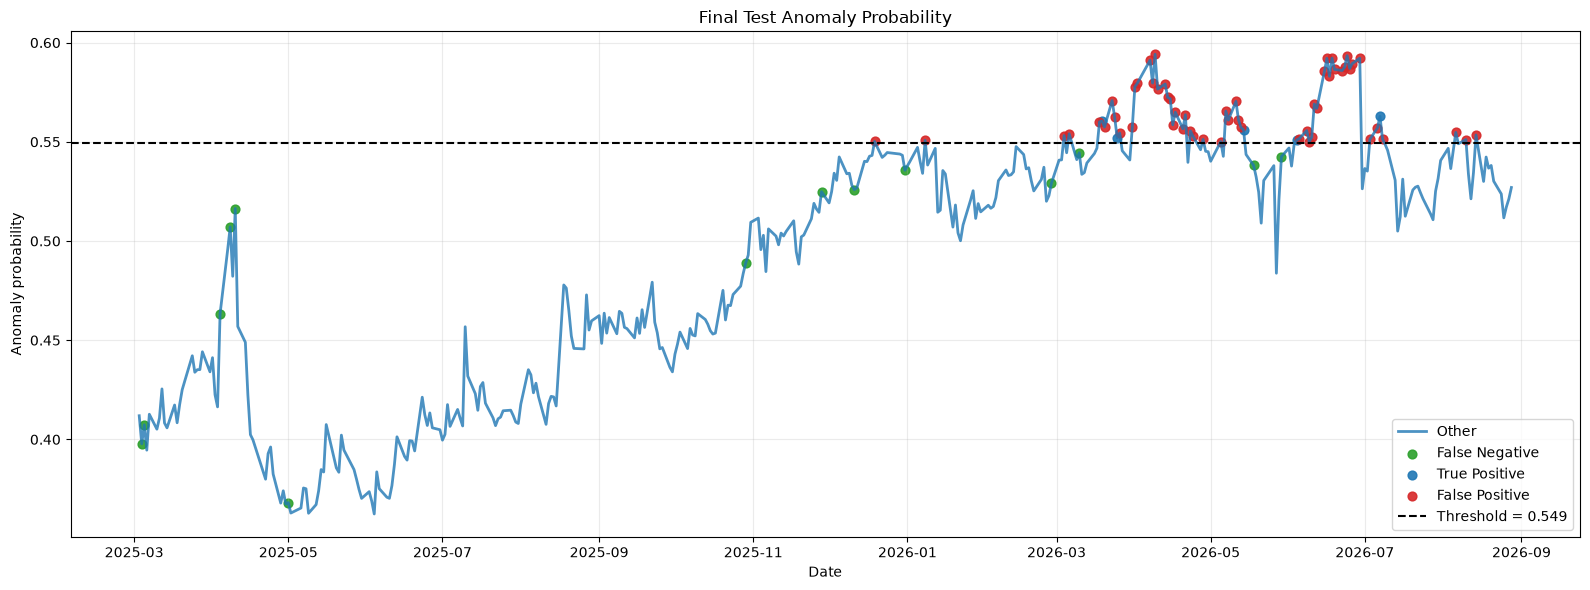

In [29]:
# Final test anomaly probability plot with TP / FP highlighted
# Grey points are shown as a line chart instead of scatter points

final_test_df = pd.DataFrame({
    "date": dates_test,
    "actual": y_test,
    "probability": y_test_prob,
    "prediction": y_test_pred
}).sort_values("date").reset_index(drop=True)

final_test_df["outcome"] = np.where(
    (final_test_df["actual"] == 1) & (final_test_df["prediction"] == 0),
    "False Negative",
    np.where(
    (final_test_df["actual"] == 1) & (final_test_df["prediction"] == 1),
    "True Positive",
    np.where(
        (final_test_df["actual"] == 0) & (final_test_df["prediction"] == 1),
        "False Positive",
        "Other"
    )
    )
)

color_map = {
    "False Negative": "#2ca02c",
    "True Positive": "#1f77b4",
    "False Positive": "#d62728",
}

plt.figure(figsize=(16, 6))

# Plot the grey "Other" group as a line
other_group = final_test_df
if not other_group.empty:
    plt.plot(
        other_group["date"],
        other_group["probability"],
        linewidth=2,
        alpha=0.8,
        label="Other"
    )

# Scatter TP and FP points
for outcome in ["False Negative", "True Positive", "False Positive"]:
    group = final_test_df[final_test_df["outcome"] == outcome]
    if not group.empty:
        plt.scatter(
            group["date"],
            group["probability"],
            s=40,
            color=color_map[outcome],
            alpha=0.9,
            label=outcome
        )

plt.axhline(
    best_threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Threshold = {best_threshold:.3f}"
)

plt.title("Final Test Anomaly Probability")
plt.xlabel("Date")
plt.ylabel("Anomaly probability")
plt.legend(loc="best")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(f"Results/Benchmark_Outputs/With_news/{Market}_News_lstm_walk_forward_final_test_probabilities.png", dpi=600)
plt.show()